In [84]:
# replicate:
# SAR Process (analytical solution for OU)
# SARh (SAR process with homotopic connections)

## Empirical functional connectivity

Columns: Index(['L Precentral Gyrus', 'R Precentral Gyrus', 'L Superior Frontal Gyrus',
       'R Superior Frontal Gyrus', 'L Superior Orbital Gyrus',
       'R Superior Orbital Gyrus', 'L Middle Frontal Gyrus',
       'R Middle Frontal Gyrus', 'L Middle Orbital Gyrus',
       'R Middle Orbital Gyrus', 'L IFG (p. Opercularis)',
       'R IFG (p. Opercularis)', 'L IFG (p. Triangularis)',
       'R IFG (p. Triangularis)', 'L IFG (p. Orbitalis)',
       'R IFG (p. Orbitalis)', 'L Rolandic Operculum', 'R Rolandic Operculum',
       'L Posterior-Medial Frontal', 'R Posterior-Medial Frontal',
       'L Olfactory cortex', 'R Olfactory cortex', 'L Superior Medial Gyrus',
       'R Superior Medial Gyrus', 'L Mid Orbital Gyrus', 'R Mid Orbital Gyrus',
       'L Rectal Gyrus', 'R Rectal Gyrus', 'L Insula Lobe', 'R Insula Lobe',
       'L Cingulum Ant', 'R Cingulum Ant', 'L Cingulum Mid', 'R Cingulum Mid',
       'L Cingulum Post', 'R Cingulum Post', 'L Hippocampus', 'R Hippocampus',
       'L Par

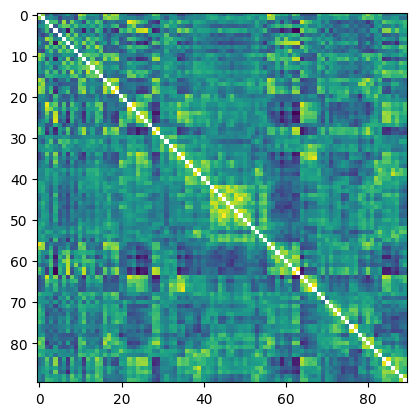

In [85]:
import matplotlib.pyplot as plt

import sys
from pathlib import Path

sys.path.append(str(Path("../..").resolve()))

from empirical_FC.import_eso import return_eso_controls, get_fc_orders, print_order_names

empirical_fc_matrix_list = return_eso_controls(printing=False)

plt.imshow(empirical_fc_matrix_list[1])

columns = empirical_fc_matrix_list[1].columns
print(f'Columns: {columns}')

print(f'Lenght of empirical fc matrix list: {len(empirical_fc_matrix_list)}')

# for matrix in matrix_list[:5]:
#     plt.imshow(matrix)
#     plt.show()


## Load in ordering

hemisphere_order,
            lobar_bilateral_order,
            lobar_hemi_order,
            subcortical_first_order,
            functional_order
Order name: hemisphere_order


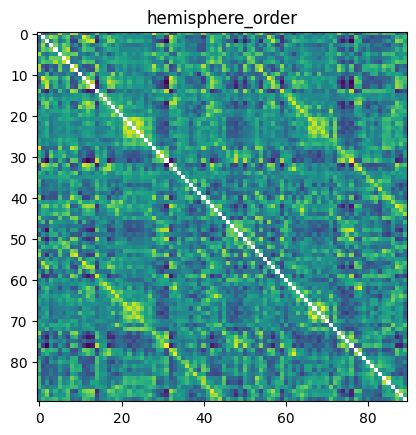

Order name: lobar_bilateral_order


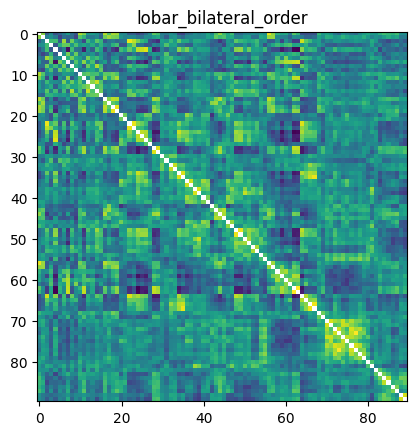

Order name: lobar_hemi_order


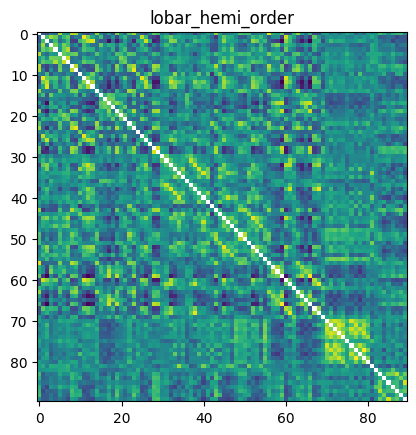

Order name: subcortical_first_order


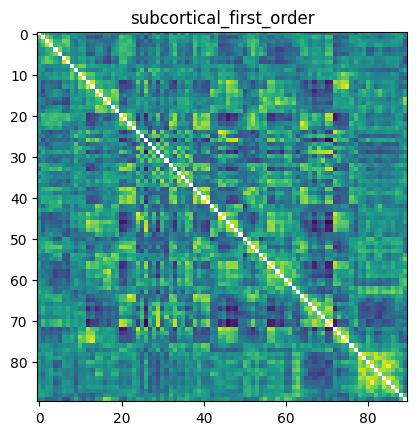

Order name: functional_order


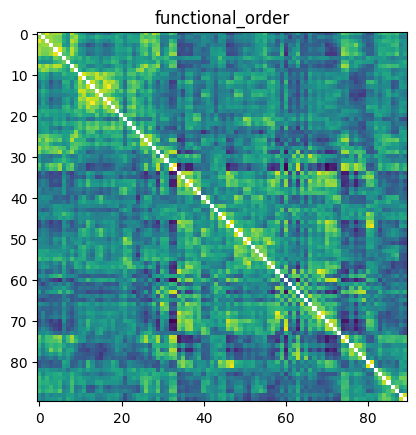

In [86]:
orders = get_fc_orders(columns)

print_order_names()

hemisphere_order, lobar_bilateral_order, lobar_hemi_order, subcortical_first_order, functional_order = get_fc_orders(columns)

named_orders = {
    'hemisphere_order': hemisphere_order,
            'lobar_bilateral_order': lobar_bilateral_order,
            'lobar_hemi_order': lobar_hemi_order,
            'subcortical_first_order': subcortical_first_order,
            'functional_order':functional_order
}

for key in named_orders.keys():
    print(f'Order name: {key}')
    order = named_orders[key]
    plt.title(key)
    plt.imshow(empirical_fc_matrix_list[1].loc[order, order])
    plt.show()

## Order empirical FC according to hemispheric

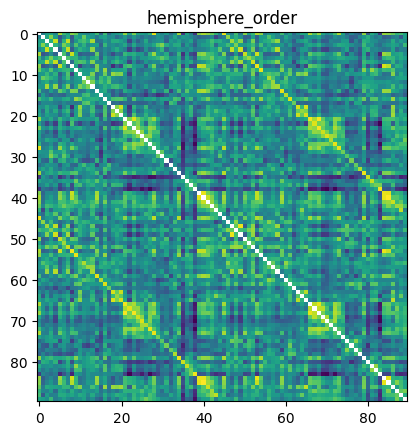

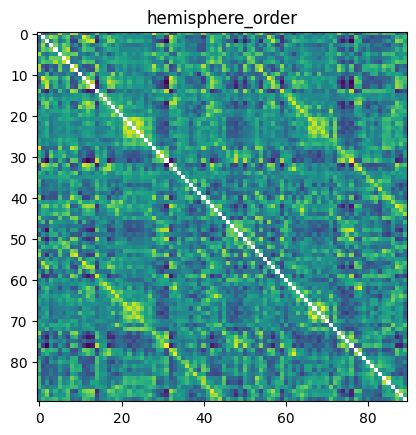

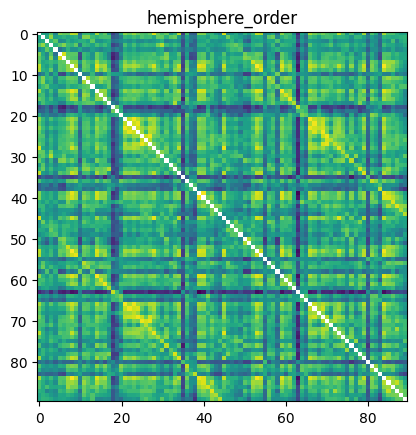

In [87]:
hemisphere_order = hemisphere_order

ordered_empfc_matrix_list = []

for index, matrix in enumerate(empirical_fc_matrix_list):
    # print(f'Index: {index}')

    ordered_matrix = matrix.loc[hemisphere_order, hemisphere_order]
    ordered_empfc_matrix_list.append(ordered_matrix)

for matrix in ordered_empfc_matrix_list[:3]:
    plt.title('hemisphere_order')
    plt.imshow(matrix)
    plt.show()

## Empirical structural connectivity

In [88]:
import matplotlib.pyplot as plt

# load in SC
import sys
from pathlib import Path

PROJECT_ROOT = Path("../..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from empirical_FC.import_eso import return_eso_controls
from empirical_SC.AAL90_skocha.import_skocha import return_skocha_sc, return_skocha_sc_dictionary

empirical_sc_matrix_list = return_skocha_sc(printing=True)

# for matrix in empirical_sc_matrix_list[:4]:
#     plt.imshow(matrix)


/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S020.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S081.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S015.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S069.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S077.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S080.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S018.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S068.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S026.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S029.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S047.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S021.csv
/store/projects/READY_TO_MODEL_william/empirical_SC/AAL90_skocha/S031.csv
/store/projects/READY_TO_MODEL_william

## Order structural FC according to hemispheric

In [89]:
hemisphere_order = hemisphere_order

ordered_emp_sc_matrix_list = []

for index, matrix in enumerate(empirical_sc_matrix_list):
    # print(f'Index: {index}')

    ordered_matrix = matrix.loc[hemisphere_order, hemisphere_order]
    ordered_emp_sc_matrix_list.append(ordered_matrix)

# for matrix in ordered_emp_sc_matrix_list[:3]:
#     plt.title('hemisphere_order')
#     plt.imshow(matrix)
#     plt.show()

## Check that ordering is identical:

In [90]:
assert (ordered_empfc_matrix_list[1].columns == ordered_emp_sc_matrix_list[1].columns).all()

## Generate average structural connectome

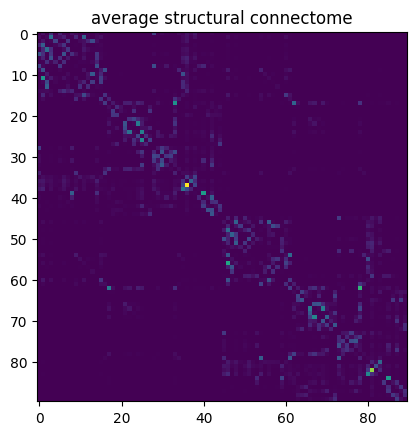

In [91]:
import numpy as np

# Average SC across subjects

sc_matrices = ordered_emp_sc_matrix_list

mean_emp_sc = np.mean(sc_matrices, axis=0)

plt.title('average structural connectome')
plt.imshow(mean_emp_sc)
plt.show()

## Generate average functional connectome

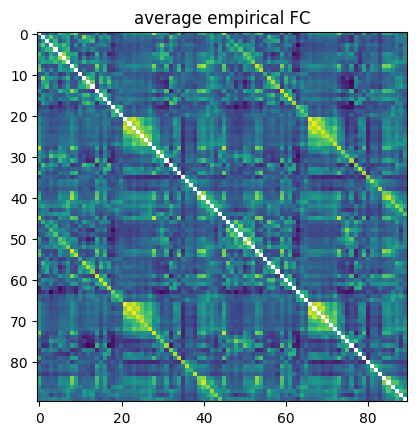

In [92]:
fc_matrices = ordered_empfc_matrix_list

# Average empirical FC across subjects
mean_emp_fc = np.mean(fc_matrices, axis=0)

plt.title('average empirical FC')
plt.imshow(mean_emp_fc)
plt.show()

## Simulated functional connectivity

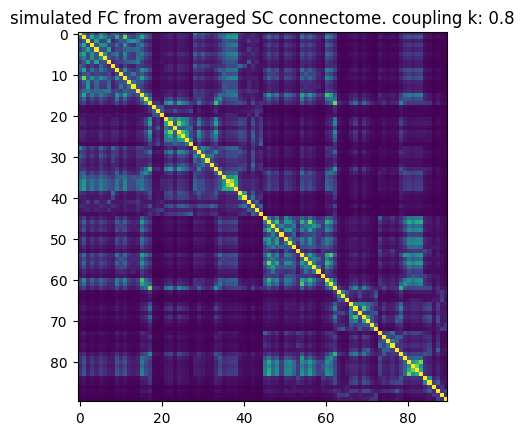

In [93]:
# SAR analytical covariance

import numpy as np
import pandas as pd


sample_sc = ordered_emp_sc_matrix_list[1]


def sar_fc(connectivity, k=0.8, sigma=1.0, normalize=True):
    """
    Predict functional connectivity from structural connectivity
    using the SAR model from Messé et al.

    Parameters
    ----------
    connectivity : pd.DataFrame or np.ndarray
        NxN structural connectivity matrix, e.g. AAL90.
    k : float
        Global coupling strength.
    sigma : float
        Noise amplitude.
    normalize : bool
        If True, normalize SC by its spectral radius.

    Returns
    -------
    fc : pd.DataFrame or np.ndarray
        NxN predicted functional connectivity matrix.
    """

    is_dataframe = isinstance(connectivity, pd.DataFrame)

    if is_dataframe:
        labels = connectivity.index
        D = connectivity.to_numpy(dtype=float)
    else:
        D = np.asarray(connectivity, dtype=float)

    # -----------------------------
    # checks
    # -----------------------------
    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("Connectivity matrix must be square.")

    # -----------------------------
    # optional spectral normalization
    # -----------------------------
    if normalize:
        spectral_radius = np.max(np.abs(np.linalg.eigvals(D)))

        if spectral_radius == 0:
            raise ValueError("Connectivity matrix has zero spectral radius.")

        D = D / spectral_radius

    # -----------------------------
    # SAR model
    #
    # y = kDy + sigma*v
    #
    # covariance:
    # Σ = σ² (I-kD)^-1 (I-kD)^-T
    # -----------------------------
    I = np.eye(D.shape[0])
    A = I - k * D

    transfer = np.linalg.solve(A, I)

    covariance = sigma**2 * transfer @ transfer.T

    # covariance -> FC correlation matrix
    std = np.sqrt(np.diag(covariance))
    fc = covariance / np.outer(std, std)

    # preserve AAL labels
    if is_dataframe:
        fc = pd.DataFrame(
            fc,
            index=labels,
            columns=labels
        )

    return fc

k = 0.8

simulated_fc = sar_fc(
    sample_sc,
    k=k
)

plt.title(f'simulated FC from averaged SC connectome. coupling k: {k}')
plt.imshow(simulated_fc)



## Generate coupling strengths

Critical coupling: 1.3695305819105836


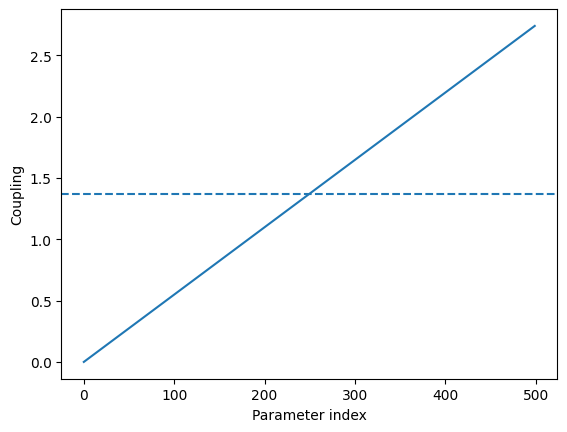

In [94]:
import numpy as np
import matplotlib.pyplot as plt

def get_critical_coupling(connectivity):
    D = np.asarray(connectivity, dtype=float)

    eigenvalues = np.linalg.eigvals(D)
    spectral_radius = np.max(np.abs(eigenvalues))

    return 1.0 / spectral_radius


crit = get_critical_coupling(mean_emp_sc)
print("Critical coupling:", crit)

couplings = np.linspace(0.0, 2.0, 500) * crit

plt.plot(range(len(couplings)), couplings)
plt.axhline(crit, linestyle="--")
plt.xlabel("Parameter index")
plt.ylabel("Coupling")
plt.show()

# Sweep coupling

In [95]:
import numpy as np
import pandas as pd

log = pd.DataFrame(columns=[
    'k',
    'corr'
])

# upper-triangle indices, excluding diagonal
tri = np.triu_indices_from(mean_emp_fc, k=1)

for coupling in couplings:

    # generate simulated FC
    sim_fc = sar_fc(
        mean_emp_sc,
        k=coupling,
        normalize=False   # important if crit was calculated from raw mean_emp_sc
    )

    # convert DataFrames if needed
    sim_fc_array = np.asarray(sim_fc, dtype=float)
    emp_fc_array = np.asarray(mean_emp_fc, dtype=float)

    # Pearson correlation between FC edges
    corr = np.corrcoef(
        sim_fc_array[tri],
        emp_fc_array[tri]
    )[0, 1]

    log.loc[len(log)] = {
        'k': coupling,
        'corr': corr
    }


print(log)

/home/wlizr/.local/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/wlizr/.local/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


            k      corr
0    0.000000       NaN
1    0.005489  0.361558
2    0.010978  0.361751
3    0.016467  0.361942
4    0.021956  0.362131
..        ...       ...
495  2.717105  0.143148
496  2.722594  0.137007
497  2.728083  0.129252
498  2.733572  0.120323
499  2.739061  0.110671

[500 rows x 2 columns]


## Maximum value in sweep

In [96]:
max_idx = log['corr'].idxmax()

max_k = log.loc[max_idx, 'k']
max_corr = log.loc[max_idx, 'corr']

print(f"Max k: {max_k}")
print(f"Max corr: {max_corr}")

Max k: 0.40619343912378025
Max corr: 0.3699109998392159


## Plot the sweep

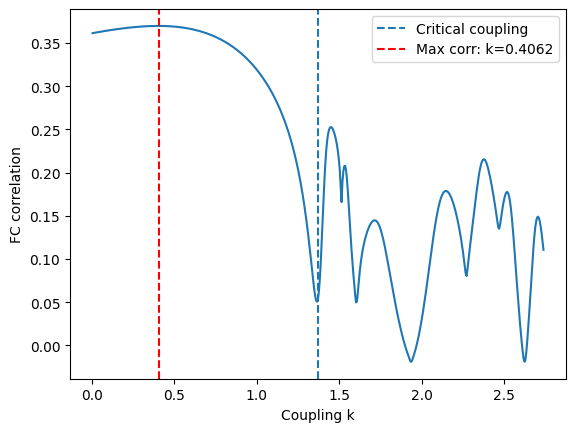

In [97]:
import matplotlib.pyplot as plt

# maximum correlation point
max_idx = log['corr'].idxmax()
max_k = log.loc[max_idx, 'k']
max_corr = log.loc[max_idx, 'corr']

plt.plot(log['k'], log['corr'])

# critical coupling
plt.axvline(
    crit,
    linestyle='--',
    label='Critical coupling'
)

# best coupling
plt.axvline(
    max_k,
    color='red',
    linestyle='--',
    label=f'Max corr: k={max_k:.4f}'
)

plt.xlabel('Coupling k')
plt.ylabel('FC correlation')

plt.legend()
plt.show()



# Setting homotopic connections

In [98]:
# %%
homotopic_strengths = [0.5, 1.0]

sarh_results = {}

# ----------------------------------------
# Default SAR — original SC unchanged
# ----------------------------------------

log_default, crit_default = run_sar_sweep(
    mean_emp_sc_df,
    mean_emp_fc
)

sarh_results['default'] = {
    'sc': mean_emp_sc_df.copy(),
    'log': log_default,
    'crit': crit_default
}


# ----------------------------------------
# SARh — modified homotopic connections
# ----------------------------------------

for h in homotopic_strengths:

    sc_h = set_homotopic_connections(
        mean_emp_sc_df,
        strength=h
    )

    log_h, crit_h = run_sar_sweep(
        sc_h,
        mean_emp_fc
    )

    sarh_results[h] = {
        'sc': sc_h,
        'log': log_h,
        'crit': crit_h
    }


# ----------------------------------------
# Print maxima
# ----------------------------------------

for name, result in sarh_results.items():

    log_i = result['log']
    crit_i = result['crit']

    max_idx = log_i['corr'].idxmax()

    print(
        f"{name} | "
        f"critical k = {crit_i:.4f} | "
        f"best k = {log_i.loc[max_idx, 'k']:.4f} | "
        f"best corr = {log_i.loc[max_idx, 'corr']:.4f}"
    )

/home/wlizr/.local/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/wlizr/.local/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


default | critical k = 1.3695 | best k = 0.4062 | best corr = 0.3699
0.5 | critical k = 0.8359 | best k = 0.5025 | best corr = 0.5273
1.0 | critical k = 0.5898 | best k = 0.4326 | best corr = 0.5148


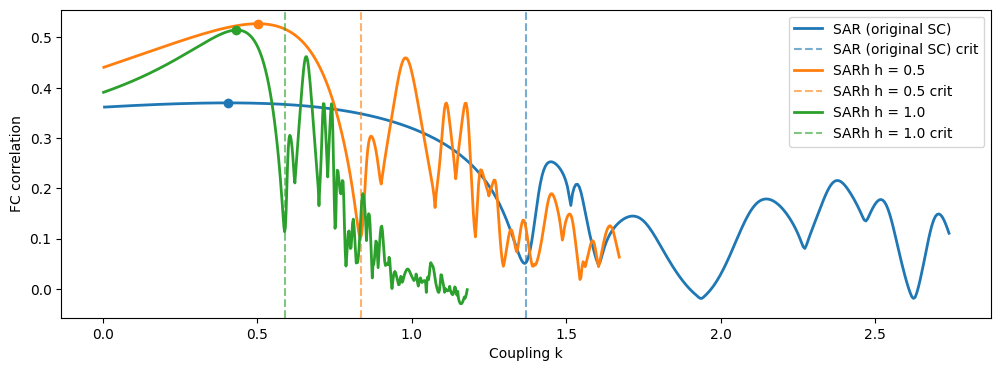

In [100]:
# %%
plt.figure(figsize=(12, 4))

for name, result in sarh_results.items():

    log_i = result['log']
    crit_i = result['crit']

    max_idx = log_i['corr'].idxmax()
    max_k = log_i.loc[max_idx, 'k']
    max_corr = log_i.loc[max_idx, 'corr']

    # nicer label
    if name == 'default':
        label = 'SAR (original SC)'
    else:
        label = f'SARh h = {name}'

    # plot line and capture its color
    line, = plt.plot(
        log_i['k'],
        log_i['corr'],
        label=label,
        linewidth=2
    )

    color = line.get_color()

    # maximum point in same color
    plt.scatter(
        max_k,
        max_corr,
        color=color,
        zorder=5
    )

    # critical coupling in same color
    plt.axvline(
        crit_i,
        color=color,
        linestyle='--',
        alpha=0.6,
        label=f'{label} crit'
    )

plt.xlabel('Coupling k')
plt.ylabel('FC correlation')
plt.legend()
plt.show()

## SIMULATE BOLD ACTIVITY BEFORE CORRELATING

In [83]:
half = len(hemisphere_order) // 2

for left, right in zip(
    hemisphere_order[:half],
    hemisphere_order[half:]
):
    print(left, '<->', right)

L Precentral Gyrus <-> R Precentral Gyrus
L Superior Frontal Gyrus <-> R Superior Frontal Gyrus
L Superior Orbital Gyrus <-> R Superior Orbital Gyrus
L Middle Frontal Gyrus <-> R Middle Frontal Gyrus
L Middle Orbital Gyrus <-> R Middle Orbital Gyrus
L IFG (p. Opercularis) <-> R IFG (p. Opercularis)
L IFG (p. Triangularis) <-> R IFG (p. Triangularis)
L IFG (p. Orbitalis) <-> R IFG (p. Orbitalis)
L Rolandic Operculum <-> R Rolandic Operculum
L Posterior-Medial Frontal <-> R Posterior-Medial Frontal
L Olfactory cortex <-> R Olfactory cortex
L Superior Medial Gyrus <-> R Superior Medial Gyrus
L Mid Orbital Gyrus <-> R Mid Orbital Gyrus
L Rectal Gyrus <-> R Rectal Gyrus
L Insula Lobe <-> R Insula Lobe
L Cingulum Ant <-> R Cingulum Ant
L Cingulum Mid <-> R Cingulum Mid
L Cingulum Post <-> R Cingulum Post
L Hippocampus <-> R Hippocampus
L ParaHippocampal Gyrus <-> R ParaHippocampal Gyrus
L Amygdala <-> R Amygdala
L Calcarine Gyrus <-> R Calcarine Gyrus
L Cuneus <-> R Cuneus
L Lingual Gyrus <-

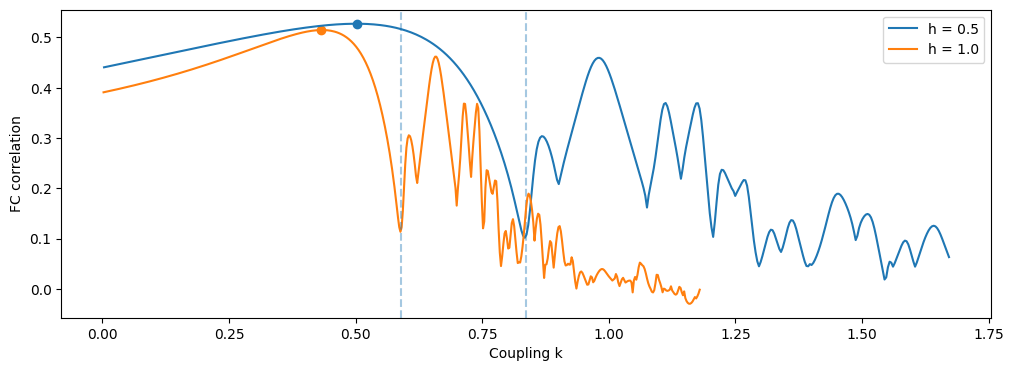

In [82]:
# %%
plt.figure(figsize=(12, 4))

for h in homotopic_strengths:

    log_h = sarh_results[h]['log']
    crit_h = sarh_results[h]['crit']

    max_idx = log_h['corr'].idxmax()
    max_k = log_h.loc[max_idx, 'k']
    max_corr = log_h.loc[max_idx, 'corr']

    plt.plot(
        log_h['k'],
        log_h['corr'],
        label=f'h = {h}'
    )

    plt.scatter(
        max_k,
        max_corr
    )

    plt.axvline(
        crit_h,
        linestyle='--',
        alpha=0.4
    )


plt.xlabel('Coupling k')
plt.ylabel('FC correlation')
plt.legend()
plt.show()